# 03 · Fine-tuned Arabic Transformers: AraBERT v0.2 and CAMeLBERT-MSA
*Model family 2 of 3. Requires a GPU: Runtime → Change runtime type → T4 GPU.*

* **Sentence-pair input** `[CLS] sentence [SEP] aspect category [SEP]`: the format that worked best on this
  dataset (Alyami et al., 2025). It uses the aspect *category*, so implicit aspects are handled too.
* **Two Arabic encoders**: AraBERT v0.2 (Antoun et al., 2020) and CAMeLBERT-MSA (Inoue et al., 2021),
  the strongest model on this dataset in Alyami et al. (2025).
* **Class weighting**: standard cross-entropy vs cross-entropy weighted by inverse class frequency.
* **Three random seeds per setting**, reported as mean ± standard deviation, so differences smaller than the
  seed-to-seed variation are not mistaken for improvements (Youseef et al., 2026).
* **Error analysis**: the highest-loss test errors and Integrated Gradients word attributions.

In [ ]:
# Install captum (for explanations), mount Google Drive and load the libraries.
import os, sys, json, time, random, subprocess, warnings, gc, html
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "captum", "accelerate"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/MAAI902_ABSA"
else:
    BASE = "./MAAI902_ABSA"
DATA_DIR, FIG_DIR, RES_DIR, MODEL_DIR = (os.path.join(BASE, d) for d in ("data", "figures", "results", "models"))
TMP_DIR = "/content/tmp_runs" if IN_COLAB else os.path.join(BASE, "tmp_runs")
for d in (FIG_DIR, RES_DIR, MODEL_DIR, TMP_DIR):
    os.makedirs(d, exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from torch import nn
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments,
                          DataCollatorWithPadding, EarlyStoppingCallback, set_seed)
from datasets import Dataset
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay, classification_report

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU – will be slow!)")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

Mounted at /content/drive
GPU: Tesla T4


## 1. Configuration
Learning rates follow Alyami et al. (2025). Class weights are w_j = N / (k · n_j), where n_j is the number of
training rows in class j and k = 3 classes.

In [ ]:
MODELS = {                                   # name -> (Hugging Face model id, learning rate)
    "AraBERTv02":   ("aubmindlab/bert-base-arabertv02", 2e-5),
    "CAMeLBERT-MSA": ("CAMeL-Lab/bert-base-arabic-camelbert-msa", 3e-5),
}
LOSSES = ["ce", "weighted_ce"]
SEEDS = [42, 13, 7]
EPOCHS, BATCH, MAX_LEN = 4, 32, 128

LABELS = ["positive", "negative", "neutral"]
label2id = {l: i for i, l in enumerate(LABELS)}; id2label = {i: l for l, i in label2id.items()}

train = pd.read_csv(f"{DATA_DIR}/train.csv")
val = pd.read_csv(f"{DATA_DIR}/val.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
for df in (train, val, test):
    df["label"] = df["sentiment"].map(label2id)

counts = train["label"].value_counts().sort_index().values
class_weights = torch.tensor(len(train) / (len(LABELS) * counts), dtype=torch.float)
print("class weights (pos, neg, neu):", class_weights.numpy().round(3))

class weights (pos, neg, neu): [0.572 0.96  4.78 ]


## 2. Training utilities

In [ ]:
def encode(tok, df):
    """Tokenise each row as a sentence pair: the cleaned sentence and the aspect category text."""
    ds = Dataset.from_pandas(df[["text_light", "category_text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tok(b["text_light"], b["category_text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["text_light", "category_text"])

class WeightedTrainer(Trainer):
    """Trainer whose loss can be class-weighted cross-entropy."""
    def __init__(self, *args, loss_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.loss_weights = loss_weights
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        w = self.loss_weights.to(outputs.logits.device) if self.loss_weights is not None else None
        loss = nn.functional.cross_entropy(outputs.logits, labels, weight=w)
        return (loss, outputs) if return_outputs else loss

def metric_fn(eval_pred):
    """Validation metrics used for early stopping and for choosing the best epoch."""
    logits, y = eval_pred
    yhat = logits.argmax(-1)
    return {"accuracy": accuracy_score(y, yhat), "macro_f1": f1_score(y, yhat, average="macro", labels=[0, 1, 2], zero_division=0)}

def scores(y_true, y_pred):
    """Accuracy, macro-F1 and per-class precision, recall and F1."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)}
    for i, l in enumerate(LABELS):
        out[f"{l}_P"], out[f"{l}_R"], out[f"{l}_F1"] = p[i], r[i], f[i]
    return out

def run(model_name, loss, seed):
    """Fine-tune one model with one loss and one seed; return its scores and test-set probabilities."""
    hf_id, lr = MODELS[model_name]
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(hf_id)
    model = AutoModelForSequenceClassification.from_pretrained(hf_id, num_labels=3, id2label=id2label, label2id=label2id)
    tr, va, te = encode(tok, train), encode(tok, val), encode(tok, test)
    out_dir = f"{TMP_DIR}/{model_name}_{loss}_{seed}"
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=EPOCHS, learning_rate=lr, per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=64, weight_decay=0.01, warmup_steps=int(0.1 * EPOCHS * np.ceil(len(train) / BATCH)),  # 10% warm-up
        eval_strategy="epoch",
        save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
        save_total_limit=1, logging_steps=50, report_to="none", seed=seed, fp16=torch.cuda.is_available())
    trainer = WeightedTrainer(model=model, args=args, train_dataset=tr, eval_dataset=va,
                              data_collator=DataCollatorWithPadding(tok), compute_metrics=metric_fn,
                              callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
                              loss_weights=class_weights if loss == "weighted_ce" else None)
    t0 = time.time(); trainer.train(); train_min = (time.time() - t0) / 60
    val_pred = trainer.predict(va).predictions.argmax(-1)
    logits = trainer.predict(te).predictions
    probs = torch.softmax(torch.tensor(logits), -1).numpy()
    res = {"model": model_name, "loss": loss, "seed": seed, "train_minutes": round(train_min, 1),
           "val_macro_f1": f1_score(val["label"], val_pred, average="macro"),
           **{f"test_{k}": v for k, v in scores(test["sentiment"], [id2label[i] for i in probs.argmax(-1)]).items()}}
    return res, probs, trainer, tok

## 3. Run all experiments
Each finished run is appended to `03_transformer_runs.csv`, so if Colab disconnects, re-running this cell
skips the runs that are already done. The model with the best **validation** macro-F1 is kept.

In [ ]:
# Loop over models, losses and seeds, skipping runs that already finished.
runs_path = f"{RES_DIR}/03_transformer_runs.csv"
done = pd.read_csv(runs_path) if os.path.exists(runs_path) else pd.DataFrame()
sel_path = f"{MODEL_DIR}/best_transformer/selection.json"
best = json.load(open(sel_path)) if os.path.exists(sel_path) else {"val_macro_f1": -1}

for model_name in MODELS:
    for loss in LOSSES:
        for seed in SEEDS:
            if len(done) and ((done.model == model_name) & (done.loss == loss) & (done.seed == seed)).any():
                print("skip (already done):", model_name, loss, seed); continue
            print(f"\n=== {model_name} | {loss} | seed {seed} ===")
            res, probs, trainer, tok = run(model_name, loss, seed)
            print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items() if k in ("val_macro_f1", "test_accuracy", "test_macro_f1", "test_neutral_F1")})
            np.save(f"{RES_DIR}/probs_{model_name}_{loss}_{seed}.npy", probs)
            done = pd.concat([done, pd.DataFrame([res])], ignore_index=True); done.to_csv(runs_path, index=False)
            if res["val_macro_f1"] > best["val_macro_f1"]:
                best = res
                trainer.save_model(f"{MODEL_DIR}/best_transformer"); tok.save_pretrained(f"{MODEL_DIR}/best_transformer")
                with open(f"{MODEL_DIR}/best_transformer/selection.json", "w") as f:
                    json.dump({k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in res.items()}, f, indent=2)
            del trainer; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None

skip (already done): AraBERTv02 ce 42
skip (already done): AraBERTv02 ce 13
skip (already done): AraBERTv02 ce 7
skip (already done): AraBERTv02 weighted_ce 42
skip (already done): AraBERTv02 weighted_ce 13
skip (already done): AraBERTv02 weighted_ce 7
skip (already done): CAMeLBERT-MSA ce 42
skip (already done): CAMeLBERT-MSA ce 13
skip (already done): CAMeLBERT-MSA ce 7
skip (already done): CAMeLBERT-MSA weighted_ce 42
skip (already done): CAMeLBERT-MSA weighted_ce 13

=== CAMeLBERT-MSA | weighted_ce | seed 7 ===


config.json:   0%|          | 0.00/468 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'val_macro_f1': 0.7349, 'test_accuracy': 0.8441, 'test_macro_f1': 0.7273, 'test_neutral_F1': np.float64(0.4069)}


## 4. Results: mean ± standard deviation over seeds

In [ ]:
# Average each setting over its three seeds.
runs = pd.read_csv(runs_path)
cols = ["test_accuracy", "test_macro_f1", "test_positive_F1", "test_negative_F1", "test_neutral_F1", "test_neutral_R", "train_minutes"]
agg = runs.groupby(["model", "loss"])[cols].agg(["mean", "std"]).round(4)
agg.to_csv(f"{RES_DIR}/03_transformer_summary.csv")
agg

test_accuracy         test_macro_f1          \
                                   mean     std          mean     std   
model         loss                                                      
AraBERTv02    ce                 0.8843  0.0012        0.7360  0.0147   
              weighted_ce        0.8304  0.0055        0.7157  0.0025   
CAMeLBERT-MSA ce                 0.8770  0.0006        0.7355  0.0058   
              weighted_ce        0.8415  0.0080        0.7236  0.0076   

                          test_positive_F1         test_negative_F1          \
                                      mean     std             mean     std   
model         loss                                                            
AraBERTv02    ce                    0.9164  0.0004           0.9076  0.0038   
              weighted_ce           0.8736  0.0068           0.8939  0.0009   
CAMeLBERT-MSA ce                    0.9123  0.0007           0.9015  0.0070   
              weighted_ce           0.8833  0.0062           0.8924  0.0017   

                          test_neutral_F1         test_neutral_R          \
                                     mean     std           mean     std   
model         loss                                                         
AraBERTv02    ce                   0.3840  0.0448         0.3235  0.0537   
              weighted_ce          0.3796  0.0057         0.5976  0.0271   
CAMeLBERT-MSA ce                   0.3927  0.0194         0.3669  0.0271   
              weighted_ce          0.3952  0.0168         0.5602  0.0123   

                          train_minutes          
                                   mean     std  
model         loss                               
AraBERTv02    ce                 4.0000  0.4000  
              weighted_ce        4.6667  0.6807  
CAMeLBERT-MSA ce                 4.2667  1.1590  
              weighted_ce        4.4000  0.9539

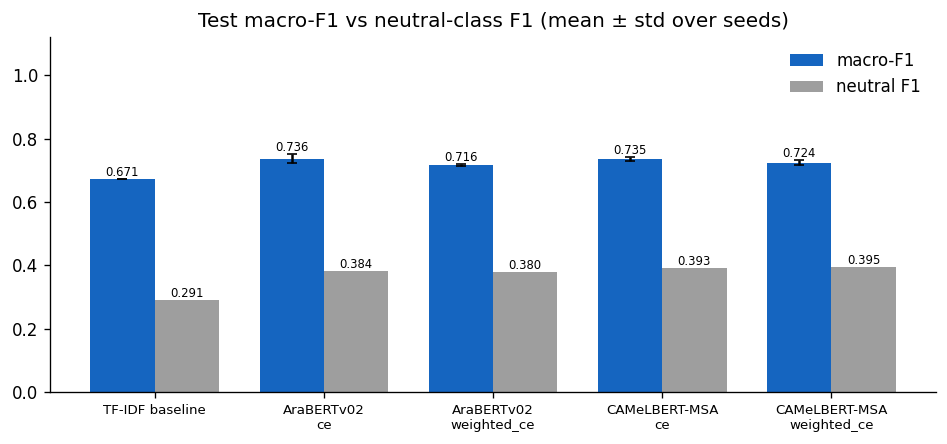

In [ ]:
# Macro-F1 next to neutral-class F1 for every configuration, with the TF-IDF baseline from notebook 02.
with open(f"{RES_DIR}/02_baseline_results.json", encoding="utf-8") as f:
    base = json.load(f)["test_best_baseline"]
plot = runs.groupby(["model", "loss"])[["test_macro_f1", "test_neutral_F1"]].agg(["mean", "std"])
names = ["TF-IDF baseline"] + [f"{m}\n{l}" for m, l in plot.index]
mf1 = [base["macro_f1"]] + list(plot[("test_macro_f1", "mean")])
mf1_sd = [0] + list(plot[("test_macro_f1", "std")].fillna(0))
nf1 = [base["neutral_F1"]] + list(plot[("test_neutral_F1", "mean")])
x = np.arange(len(names)); w = .38
fig, ax = plt.subplots(figsize=(8, 3.8))
b1 = ax.bar(x - w/2, mf1, w, yerr=mf1_sd, capsize=3, label="macro-F1", color="#1565C0")
b2 = ax.bar(x + w/2, nf1, w, label="neutral F1", color="#9E9E9E")
ax.bar_label(b1, fmt="%.3f", fontsize=7); ax.bar_label(b2, fmt="%.3f", fontsize=7)
ax.set_xticks(x, names, fontsize=8); ax.set_ylim(0, 1.12); ax.legend(frameon=False)
ax.set_title("Test macro-F1 vs neutral-class F1 (mean ± std over seeds)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig5_model_comparison.png", bbox_inches="tight"); plt.show()

In [ ]:
# Comparison with the most recent published results on the same dataset. The published set-ups use different
# validation splits and de-duplication, so this shows whether the results are in the expected range rather than
# a strict leaderboard.
bm = pd.DataFrame([
    ["Alyami et al. (2025) – In-DAPT CAMeLBERT-MSA", 89.67, 75.16],
    ["Alyami et al. (2025) – + focal loss & class weights", 89.86, 78.63],
], columns=["system", "accuracy_%", "macro_F1_%"])
ours = runs.groupby(["model", "loss"])[["test_accuracy", "test_macro_f1"]].mean().reset_index()
for _, r in ours.iterrows():
    bm.loc[len(bm)] = [f"OURS – {r['model']} ({r['loss']})", round(r.test_accuracy * 100, 2), round(r.test_macro_f1 * 100, 2)]
bm.loc[len(bm)] = ["OURS – TF-IDF baseline", round(base["accuracy"] * 100, 2), round(base["macro_f1"] * 100, 2)]
bm.to_csv(f"{RES_DIR}/03_benchmark_table.csv", index=False)
bm

,system,accuracy_%,macro_F1_%
0,Alyami et al. (2025) – In-DAPT CAMeLBERT-MSA,89.67,75.16
1,Alyami et al. (2025) – + focal loss & class we...,89.86,78.63
2,OURS – AraBERTv02 (ce),88.43,73.60
3,OURS – AraBERTv02 (weighted_ce),83.04,71.57
4,OURS – CAMeLBERT-MSA (ce),87.70,73.55
5,OURS – CAMeLBERT-MSA (weighted_ce),84.15,72.36
6,OURS – TF-IDF baseline,81.95,67.12


## 5. Best model: detailed test evaluation
The best model was chosen by validation macro-F1; here it is evaluated on the test set.

Best model: AraBERTv02 weighted_ce seed 7
              precision    recall  f1-score   support

    positive      0.932     0.829     0.878      1508
    negative      0.903     0.887     0.895       927
     neutral      0.283     0.592     0.383       169

    accuracy                          0.834      2604
   macro avg      0.706     0.769     0.719      2604
weighted avg      0.880     0.834     0.852      2604



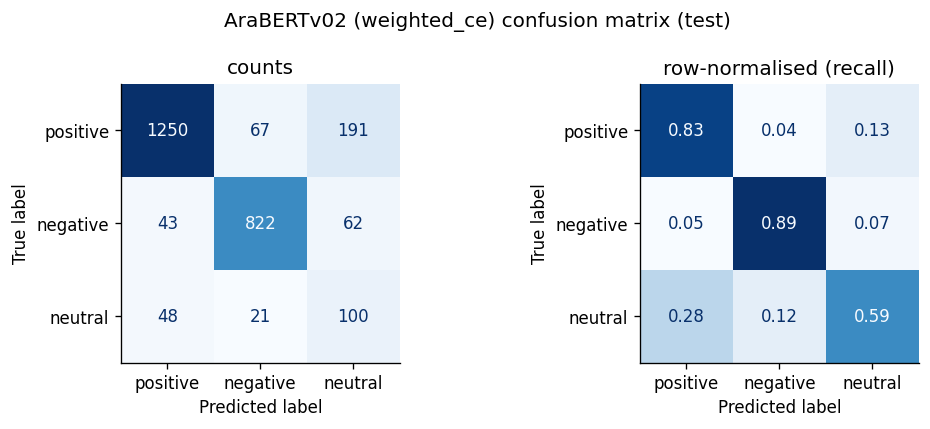

In [ ]:
# Per-class report and confusion matrix for the selected model.
sel = json.load(open(f"{MODEL_DIR}/best_transformer/selection.json"))
print("Best model:", sel["model"], sel["loss"], "seed", sel["seed"])
probs = np.load(f"{RES_DIR}/probs_{sel['model']}_{sel['loss']}_{sel['seed']}.npy")
test["pred_transformer"] = [id2label[i] for i in probs.argmax(-1)]
test["conf_transformer"] = probs.max(-1)
test["loss_transformer"] = -np.log(probs[np.arange(len(test)), test["label"].values] + 1e-12)
print(classification_report(test["sentiment"], test["pred_transformer"], labels=LABELS, digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, norm, title in [(axes[0], None, "counts"), (axes[1], "true", "row-normalised (recall)")]:
    ConfusionMatrixDisplay.from_predictions(test["sentiment"], test["pred_transformer"], labels=LABELS, normalize=norm,
                                            cmap="Blues", ax=ax, colorbar=False, values_format=".2f" if norm else "d")
    ax.set_title(title)
fig.suptitle(f"{sel['model']} ({sel['loss']}) confusion matrix (test)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig6_transformer_confusion.png", bbox_inches="tight"); plt.show()

In [ ]:
# Where do the baseline and the transformer differ? Macro-F1 on contrast sentences, implicit aspects and each entity.
preds = pd.read_csv(f"{RES_DIR}/predictions_test.csv")
preds = preds.merge(test[["row_id", "pred_transformer", "conf_transformer", "loss_transformer"]], on="row_id", how="left")
preds.to_csv(f"{RES_DIR}/predictions_test.csv", index=False)

def sl(mask):
    g = preds[mask]
    return pd.Series({"n": len(g),
                      "baseline_macroF1": f1_score(g.sentiment, g.pred_baseline, average="macro", labels=LABELS, zero_division=0),
                      "transformer_macroF1": f1_score(g.sentiment, g.pred_transformer, average="macro", labels=LABELS, zero_division=0)})
slice_tbl = pd.DataFrame({"all": sl(preds.index == preds.index), "contrast marker": sl(preds.has_contrast), "no contrast": sl(~preds.has_contrast),
                          "implicit aspect": sl(preds.implicit), "explicit aspect": sl(~preds.implicit)}).T.round(3)
ent_tbl = preds.groupby("entity").apply(lambda g: sl(preds.index.isin(g.index))).round(3).sort_values("transformer_macroF1")
slice_tbl.to_csv(f"{RES_DIR}/03_slices.csv"); ent_tbl.to_csv(f"{RES_DIR}/03_per_entity.csv")
slice_tbl

,n,baseline_macroF1,transformer_macroF1
all,2604.0,0.671,0.719
contrast marker,610.0,0.593,0.618
no contrast,1994.0,0.688,0.752
implicit aspect,232.0,0.647,0.707
explicit aspect,2372.0,0.673,0.719


In [ ]:
# Macro-F1 per entity, weakest first.
ent_tbl

,n,baseline_macroF1,transformer_macroF1
entity,,,
LOCATION,303.0,0.480,0.581
ROOMS_AMENITIES,160.0,0.588,0.679
SERVICE,560.0,0.614,0.681
FOOD_DRINKS,236.0,0.705,0.686
FACILITIES,340.0,0.656,0.712
ROOMS,312.0,0.657,0.734
HOTEL,693.0,0.691,0.762


## 6. Error analysis: the 50 highest-loss test errors
These errors are exported for a manual audit by a native Arabic speaker. Each row is labelled in the
`my_error_type` column with one of the four error types of Zaid et al. (2025), so the results can be compared
with theirs, or one of three types specific to this dataset:

| Type | Meaning |
|---|---|
| `mixed_sentiment` | praise and criticism in the same sentence (e.g. …لكن…) |
| `aspect_masking` | a strong opinion about another aspect decides the label |
| `keyword_overreliance` | one strong word such as رائع or جميل decides the label |
| `sarcasm_ambiguity` | irony or understatement |
| `label_noise` | the gold label itself looks wrong |
| `implicit` | the aspect is never named in the sentence |
| `dialect` | dialect wording the model misreads |
| `other` | none of the above |

In [ ]:
# The 50 test errors with the highest loss, with automatic flags for confident errors and contrast words.
err = preds[preds.sentiment != preds.pred_transformer].sort_values("loss_transformer", ascending=False).head(50)
err = err[["row_id", "sentence", "category", "sentiment", "pred_transformer", "conf_transformer", "pred_baseline", "has_contrast", "implicit"]].copy()
err["auto_flag"] = np.where(err.conf_transformer > 0.9, "confident-wrong → check label",
                     np.where(err.has_contrast, "contrast marker", ""))
err["my_error_type"] = ""
err.to_csv(f"{RES_DIR}/03_error_analysis_top50.csv", index=False, encoding="utf-8-sig")   # utf-8-sig keeps Arabic readable in Excel
print(err["auto_flag"].value_counts())
err.head(10)

auto_flag
confident-wrong → check label    46
                                  2
contrast marker                   2
Name: count, dtype: int64


,row_id,sentence,category,sentiment,pred_transformer,conf_transformer,pred_baseline,has_contrast,implicit,auto_flag,my_error_type
2498,2498,بعض النواقص وعلى قلتها: ضعف الانترنت في الغرف،...,FACILITIES#MISCELLANEOUS,neutral,negative,0.979988,negative,False,False,confident-wrong → check label,
2499,2499,بعض النواقص وعلى قلتها: ضعف الانترنت في الغرف،...,FACILITIES#MISCELLANEOUS,neutral,negative,0.979988,negative,False,False,confident-wrong → check label,
1896,1896,جودة الغرفة غرفة من الدرجة الثانية. غرفة قديم...,ROOMS#QUALITY,neutral,negative,0.982017,negative,False,False,confident-wrong → check label,
880,880,الخدمه سيئة جدا حيث يتم تنظيف ارضية الحمام فقط...,FACILITIES#CLEANLINESS,positive,negative,0.983812,negative,False,False,confident-wrong → check label,
313,313,والإفطار متوسط على أفضل تقدير، وهو فندق تجاري ...,SERVICE#GENERAL,negative,neutral,0.848568,neutral,False,True,,
2048,2048,غرفة رثّة سيئة الإضاءة، الخدمة كانت تُقدم باهت...,SERVICE#GENERAL,neutral,negative,0.978161,negative,True,False,confident-wrong → check label,
205,205,كوكوماما : بيت شباب رايق مع الراحة أقمنا 3 لي...,FOOD_DRINKS#QUALITY,negative,neutral,0.921020,positive,False,False,confident-wrong → check label,
2556,2556,أجمل إجازة إجازة رائعه مع محترم و إدارة مصري...,SERVICE#GENERAL,neutral,positive,0.983728,positive,False,False,confident-wrong → check label,
947,947,موقع الفندق و المطاعم والكافيات و السوبر ماركت...,HOTEL#QUALITY,negative,neutral,0.895978,positive,False,True,,
1245,1245,و تعامل المدير المناوب سيء و يعتقد أننا بمجرد ...,SERVICE#GENERAL,positive,negative,0.975749,negative,False,False,confident-wrong → check label,


## 7. Explainability: Integrated Gradients word attributions
Which words pushed the best model towards its prediction? Integrated Gradients (Sundararajan et al., 2017)
assigns each token a score; green tokens push towards the predicted class and red tokens push against it.
The result is saved as an HTML page (Arabic renders correctly in a browser) and as JSON.

In [ ]:
# Load the best model and attribute its predictions to input tokens.
from captum.attr import LayerIntegratedGradients

ig_model = AutoModelForSequenceClassification.from_pretrained(f"{MODEL_DIR}/best_transformer").eval()
ig_tok = AutoTokenizer.from_pretrained(f"{MODEL_DIR}/best_transformer")
device = "cuda" if torch.cuda.is_available() else "cpu"
ig_model.to(device)

def forward_logits(input_ids, attention_mask, token_type_ids):
    return ig_model(input_ids=input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids).logits

lig = LayerIntegratedGradients(forward_logits, ig_model.base_model.embeddings.word_embeddings)

def explain(sentence, category_text, target_label=None, steps=32):
    """Integrated Gradients attribution of each token, normalised to [-1, 1]."""
    enc = ig_tok(sentence, category_text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    tti = enc.get("token_type_ids", torch.zeros_like(enc["input_ids"]))
    with torch.no_grad():
        pred = forward_logits(enc["input_ids"], enc["attention_mask"], tti).argmax(-1).item()
    target = label2id[target_label] if target_label else pred
    baseline = torch.full_like(enc["input_ids"], ig_tok.pad_token_id)
    baseline[0, 0], baseline[0, -1] = enc["input_ids"][0, 0], enc["input_ids"][0, -1]
    attr = lig.attribute(enc["input_ids"], baselines=baseline, additional_forward_args=(enc["attention_mask"], tti),
                         target=target, n_steps=steps).sum(-1).squeeze(0)
    attr = (attr / (attr.abs().max() + 1e-9)).detach().cpu().numpy()
    toks = ig_tok.convert_ids_to_tokens(enc["input_ids"][0])
    return toks, attr, id2label[pred]

def to_html(toks, attr, title):
    """Colour each token green or red by the sign and size of its attribution."""
    spans = []
    for t, a in zip(toks, attr):
        if t in ("[CLS]", "[PAD]"): continue
        col = f"rgba(46,125,50,{abs(a):.2f})" if a > 0 else f"rgba(198,40,40,{abs(a):.2f})"
        spans.append(f'<span style="background:{col};padding:2px 3px;margin:1px;border-radius:3px">{html.escape(t)}</span>')
    return f'<div style="margin:10px 0;font-family:Arial"><b>{html.escape(title)}</b><div dir="rtl" style="font-size:18px;line-height:2">{" ".join(spans)}</div></div>'

blocks = ['<meta charset="utf-8"><h3>Integrated Gradients – green pushes TOWARDS the predicted class, red pushes AGAINST</h3>']
# Explain six of the worst errors and three correct predictions.
examples = pd.concat([err.head(6), preds[preds.sentiment == preds.pred_transformer].sample(min(3, len(preds)), random_state=1)])
ig_records = []
for _, r in examples.iterrows():
    toks, attr, pred = explain(r.sentence if isinstance(r.sentence, str) else "", r.category.replace("#", " ").replace("_", " ").lower())
    blocks.append(to_html(toks, attr, f"gold={r.sentiment} | predicted={pred} | aspect={r.category}"))
    keep = [(t, float(a)) for t, a in zip(toks, attr) if t not in ("[CLS]", "[PAD]")]
    ig_records.append({"sentence": r.sentence, "category": r.category, "gold": r.sentiment, "pred": pred,
                       "correct": bool(pred == r.sentiment), "tokens": [t for t, _ in keep], "attr": [round(a, 3) for _, a in keep]})
with open(f"{FIG_DIR}/fig7_integrated_gradients.html", "w", encoding="utf-8") as f:
    f.write("\n".join(blocks))
with open(f"{RES_DIR}/03_ig_examples.json", "w", encoding="utf-8") as f:
    json.dump(ig_records, f, ensure_ascii=False, indent=1)
try:
    from IPython.display import HTML, display; display(HTML("\n".join(blocks)))
except Exception:
    pass
print("Saved:", f"{FIG_DIR}/fig7_integrated_gradients.html")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/MAAI902_ABSA/figures/fig7_integrated_gradients.html
